In [ ]:
# script for computing NN for a homogeneous half-space
# for spherical cavities and stochastic plane Rayleigh wave propagating
import numpy as np
import os
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from scipy.io import savemat
from scipy.io import loadmat
from scipy.integrate import quad, tplquad, dblquad
import scipy.constants as const

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import createDB
from modules import NNGeometryNN
from modules import gfLoader
from modules import simDisp
from modules import NNCompute

def main():

    # load the config file
    # can be loaded for half and full homogeneous space, modify the name of the configfile accordingly
    configFile="/home/koley/CavityResults/SphereRayTutorial/StochWave/configParseHalfSpaceRayHomo.ini"
    config = configLoader.load_config(configFile)
    
    fullSpace = False # switch between full space and half space, only applicable for body wavefield simulation
    # load all cavities
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphereRayTutorial/StochWave/SingleSphCavityHalfSpace.ini')
    validateInputs.validateInputs(config)
    
    splitAll = createDB.createFinalInputs(config)

    print(f"Prepared {splitAll.shape[0]} total runs")
    print(f"Cores available: {config.cpuCoresQseis}")

    #results = createDB.runMultiQseis(splitAll, config.inputPath, config.qseisExe, nWorkers = config.cpuCoresQseis)
    
    print("Database generation complete")
    # flag for pure Rayleigh wavefield in homogeneous half-space
    ifRay = config.ifRay
    # flag for plane P and S waves in homogeneous half space
    ifBody = config.ifBody
    # flag for wavefield simulation
    ifFullField = config.ifFullField
    saveHV = config.saveHV
    thickness = config.thickness # units in meters
    vs = config.vS # units in m/s
    vp = config.vP # units in m/s
    rho = config.rho # units in kg/m^3
    rhoAir = config.rhoAir # density of air
    fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
    lambdaFrac = config.lambdaFrac # fraction
    lambdaRes = config.lambdaRes; #must be greater than 4
    
    # given a cuboidal domain should be greater than sqrt of 
    xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
    zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
    maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
    xCenter = config.xCenter; yCenter = config.yCenter
    xMin = xCenter-config.xExtent; xMax = xCenter+config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
    yMin = yCenter-config.yExtent; yMax = yCenter+config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
    zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)

    # check if the GFs are generated up to correct hoizontal offsets
    xDiag = (xMax-xMin)*np.sqrt(2); yDiag = (yMax-yMin)*np.sqrt(2);
    if(xMaxGF<xDiag or xMaxGF<yDiag):
        raise ValueError("xMaxGF must be >= sqrt(2)x(xMax-xMin) and sqrt(2)x(yMax-yMin)")

    if(zMaxGF<zMax):
        raise ValueError("zMaxGF must be greater >= zMax")
        
    domXYBounds = (xMin,xMax,yMin,yMax)

    # specify test-mass locations, this was originally defined after cubeTop cubeBot definition
    itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
    
    print('itmAC = ' + str(itmAC[0]) + ', ' + str(itmAC[1]) + ', ' + str(itmAC[2]))
    # make itmAC[2] negative, because in the configfile it is positive
    itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
    itmABUse = itmAB.copy(); itmABUse[2] = -np.abs(itmABUse[2])
    etmCAUse = etmCA.copy(); etmCAUse[2] = -np.abs(etmCAUse[2])
    etmBAUse = etmBA.copy(); etmBAUse[2] = -np.abs(etmBAUse[2])
    
    itmAll = np.vstack((itmACUse,))
    nTM = len(itmAll[:,0])
    G = const.G
    
    # an addition from the older version, where it is important to note that which cavity hosts
    # which test-mass
    tmInCavity = NNGeometryNN.findTMInCavity(allCavities, itmAll)

    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    print('grid size in each layer before partitioning = ' + str(gridSize))

    # get the background gridsize in the layer hosting the cavities
    hBGAll = NNGeometryNN.getHBG(thickness,allCavities,gridSize)
    print('hBGAll = ' + str(hBGAll))
    etaUse = 0.5
    # now get the refinement extent for all cavities
    wallRefineWidthAll = NNGeometryNN.getRefineWidths(tmInCavity, allCavities, hBGAll,eta=etaUse,
                                                          minRefine=20.0,)
    
    print('wallRefineWidth = ')
    print(wallRefineWidthAll)

    #refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll)
    refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll,domainZBounds=(zMin,zMax))

    cubeTopAll = np.zeros((len(allCavities),))
    cubeBotAll = np.zeros((len(allCavities),))
    for boxNo, box in enumerate(refineBoxes):
        cubeTopAll[boxNo] = box.zMin
        cubeBotAll[boxNo] = box.zMax
    cubeTop = min(cubeTopAll)
    cubeBot = max(cubeBotAll)
    # new part added
    
    cavDepthAll = np.zeros((len(allCavities),))
    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            cavDepthAll[cavNo] = cav["zC"]
        else:
            ValueError('Unsupported cavity type')
    cavDepthUse = min(cavDepthAll)

    print("CubeTop = " + str(cubeTop) +  'CubeBot = ' + str(cubeBot))
    
    # some other inputs for simDisp
    maxRec = config.maxRec; # same value of number of receivers that qseis can handle in one go check qsglobal.h
    tMax = config.tMax; nSamp = config.nSamp
    
    # specify the folder where you want to write all input files, should have rw access
    # fInpPath is the path where the Green's function database exists
    fInpPath = config.inputPath #like "/data/gravwav/koley/QseisInpN/"
    #fInpPath = "/data/gravwav/koley/SALVUSOut/"

    # outDispPath should have rw access and is used for saving temp displacementy files
    outDispPath = config.outDispPath # like "/data/gravwav/koley/OutDisp/"

    # saves the NN and displacement values per realization
    outDispRea = config.outDispPathRea # like "/data/gravwav/koley/OutDispRea/"
    
    # GF components to be used
    components = ['fh-2.tz', 'fh-2.tr', 'fh-2.tt', 'fz-2.tz', 'fz-2.tr']

    # splitAll is necessary so load it
    nRea = config.nRea # number of realizations

    # this file is created at the time of database generation
    splitFileName = fInpPath + 'splitAll.mat'
    splitMat = loadmat(splitFileName)
    splitAll = splitMat['splitAll']

    # source distribution parameters
    R1 = config.R1; R2 = config.R2
    nSrc = config.nSrc
    srcDistri = config.srcDistri
    scaleVH = config.scaleVH
    # flag if NN is computed directly without writing the displacemnet field
    onFlyNN = config.onFlyNN 

    # number of CPUs to be used for displacement and NN simulation
    nCPUDisp = config.cpuCoresDisp
    nCPUNN = config.cpuCoresNN
    computeStrategy = config.computeStrategy

    # frequency axis to be used by simDisp
    freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
    nFreq = len(freqOut)

    splitAllNew = gfLoader.assembleQseisRuns(splitAll, fInpPath, components, outPath=None, fIndices=idxFreq, onlySplitAll = True, minVel=100.0)
    #splitAllNew = np.load(os.path.join(fInpPath,'splitAllNew.npy'))

    # in case only Rayleigh waves in homogeneous half space is used, Rayleigh wave phase velocity is needed
    if(ifRay):
        periods = 1/freqOut
        vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    else:
        vR = None
    # two depth points for scaling, displacement saved per realization
    zList = [0.0,cavDepthUse]
    
    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    
    print('grid size in each layer before partitioning = ' + str(gridSize))
    
    # create the layers and partition
    layers, vp2, vs2, rho2, gridSize2 = NNGeometryNN.createAllLayers(xMin, xMax, yMin, yMax, thickness,
                                                                     zMax,vp,vs,rho,gridSize,cubeTop,cubeBot,
                                                                     maxHostThickness=np.ceil(cubeBot-cubeTop))
    print('New gridSize after partioning = '+ str(gridSize2))

    print('Total number of layers = ' + str(len(layers)))
    nLayers = len(layers)
    
    for reaNo in range(0,nRea):
        print('Doing realization = ' +str(reaNo))
        # get the source distribution per realization
        xSrc, ySrc, azSrc, srcMeta =  simDisp.genAmbSrc(nSrc , mode = srcDistri, R1 = R1, R2 = R2, xMin=xMin, xMax=xMax, yMin=yMin,
                                           yMax=yMax, randomPhase=True, freqDependent=True, nFreq=nFreq, decoupledHV=config.decoupledHV,
                                           scaleVH = scaleVH)
        
        # in case the body wave in homogeneous half-space flag is turned on
        if(ifBody):
            metaBody = simDisp.genBodySrc(nSrc, nFreq, eP = 1/3, eS = 2/3)
        else:
            metaBody=None
        
        # create and save the displacement field on surface and depth for scaling afterwards
        if(ifRay):
            # uses ambient Rayleigh wavefield in homogeneous half space
            phiSrc = srcMeta["phiV"]; ampSrc = srcMeta["ampV"]
            simDisp.getSurfDeepRayDispPerRea(zList, azSrc, phiSrc, ampSrc, outDispRea, reaNo, vR,
                                             vp2[0], vs2[0], freqOut=freqOut)
        elif(ifBody):
            # uses Plane P and S wave in homogeneous half space
            simDisp.getSurfDeepBodyDispPerRea(zList, metaBody, outDispRea, reaNo, vp2[0], vs2[0], freqOut=freqOut)
        
        else:
            # uses QSEIS full wavefield simulation instead
            simDisp.getSurfDeepDispPerRea(zList, xSrc, ySrc, azSrc, srcMeta, xMaxGF, splitAll, fMin, fMax, outDispRea,
                    fInpPath, components, reaNo, idxFreq = idxFreq, freqOut=freqOut)
        
        # preallocate per realization
        IBlockTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        IVertFaceTot  = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        IHorFaceTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        ITot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        
        for layerNo, layer in enumerate(layers):
            layer = layers[layerNo]

            # need to redefine cubeTop and cubeBot for multiple cavities
            layer.updateCubeInteraction(cubeTop, cubeBot)
            #layer.generateBlocks(xMin, xMax, yMin, yMax, cubeC, ax, ay, az, domXYBounds)
            layer.generateBlocksNew(refineBoxes=refineBoxes,domXYBounds=domXYBounds,
                                    domainZBounds=(zMin, zMax))
            
            print(layer)
            blkNo = 1
            for blk in layer.blocks:
                print(blk);
                print('Block = '+str(blkNo))
                print('Integrating volume  NN block in layer' + str(layerNo))

                # new version signature
                IBlock = NNCompute.runVolNNComputeBlock(blk, gridSize2[layerNo], freqOut, allCavities, itmAll,
                                                        xSrc, ySrc, azSrc,srcMeta, idxFreq, fMin, fMax, outDispPath, splitAll, xMaxGF,
                                                        fInpPath, components, vR, useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody,
                                                        nCPUDisp=nCPUDisp, nCPUNN=nCPUNN, nChunk=20000,metaBody=metaBody,
                                                        computeStrategy=computeStrategy,saveHV=saveHV)
                # new version
                IBlockTot = IBlockTot + IBlock

                # now compute the surface NN from the vertical faces of the block which form the outer boundary
                for f in blk.verticalFaces:
                    if(f.isBoundary):
                        print('Integrating vertical surface NN block in layer' + str(layerNo))
                        print('vertical boundary face found')
                        # is an outer boundary
                        IVertFace = NNCompute.runVertSurfNNCompute(f, gridSize2[layerNo], freqOut, itmAll, xSrc, ySrc, azSrc,
                                                         srcMeta, idxFreq, fMin, fMax, outDispPath, splitAllNew,
                                                         xMaxGF, fInpPath, components, vR, nCPUDisp=1, nChunk = 20000, 
                                                         useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody, vP_for_test=blk.vP,
                                                         vS_for_test=blk.vS, metaBody=metaBody,
                                                         computeStrategy=computeStrategy,saveHV=saveHV, reduceNN=onFlyNN)
                        
                        IVertFaceTot = IVertFaceTot + IVertFace
        
                
                # now compute the surface NN from the horizontal interfaces at the very end of layers
                print('Integrating horizontal surface NN block in layer' + str(layerNo))
                IHorFace = NNCompute.handleHorSurfNN(layer, layers, blk, gridSize2[layerNo], nLayers, layerNo, rhoAir, freqOut, 
                                           allCavities, itmAll, xSrc, ySrc, azSrc, srcMeta, idxFreq, fMin, fMax, outDispPath,
                                           splitAllNew, xMaxGF, fInpPath, components, vR, nCPUDisp=nCPUDisp,
                                           nCPUNN=nCPUNN, useSimDisp = ifFullField, ifRay = ifRay, ifBody = ifBody,
                                           vP_for_test=blk.vP, vS_for_test = blk.vS, metaBody = metaBody, chunk_size=20000,
                                           computeStrategy=computeStrategy, saveHV=saveHV, reduceNN=onFlyNN,fullSpace=fullSpace)
                                
                IHorFaceTot = IHorFaceTot + IHorFace
                
                blkNo = blkNo+1
    
        IVertFaceTot = IVertFaceTot*G
        IHorFaceTot = IHorFaceTot*G
        IBlockTot = IBlockTot*G
        ITot = (IBlockTot-IVertFaceTot-IHorFaceTot)
        # save the NN per realization
        nnFName = 'NNFullRea' + str(reaNo) + '.npz'
        np.savez(os.path.join(outDispRea, nnFName), IVertFaceTot = IVertFaceTot, IHorFaceTot = IHorFaceTot,
                 IBlockTot = IBlockTot, ITot = ITot, freqOut=freqOut)

if __name__ == "__main__":
    main()

All configuration and model checks passed.
Layer depths = [   0. 4000.]
Number of points per layer along Z = [100]
Spacing in each layer in meters = [39.85153559 42.19409283]
Qseis Inputs cleaned, parent folder intact.
Creating all input files ...
All input files created!
Prepared 505 total runs
Cores available: 64
Database generation complete
itmAC = 0.0, 0.0, 250.0
grid size in each layer before partitioning = [39.85153559 42.19409283]
hBGAll = [39.85153559]
wallRefineWidth = 
[np.float64(219.1092135356021)]
CubeTop = 10.890786464397934CubeBot = 489.10921353560207
[0.    0.025 0.05  0.075 0.1  ]
grid size in each layer before partitioning = [39.85153559 42.19409283]
Layer depths given by user before partitioning = [   0. 3000.] m
New layer depths after partitioning for computationional speed = [   0.    10.5  489.5 3000. ] m
New gridSize after partioning = [39.85153559 39.85153559 39.85153559]
Total number of layers = 3
Doing realization = 0
<Layer z: 0.0-10.5, type: no_intersection,

KeyboardInterrupt: 

All configuration and model checks passed.
[0.    0.025 0.05  0.075 0.1  ]
(60, 3, 2)
(60, 3)


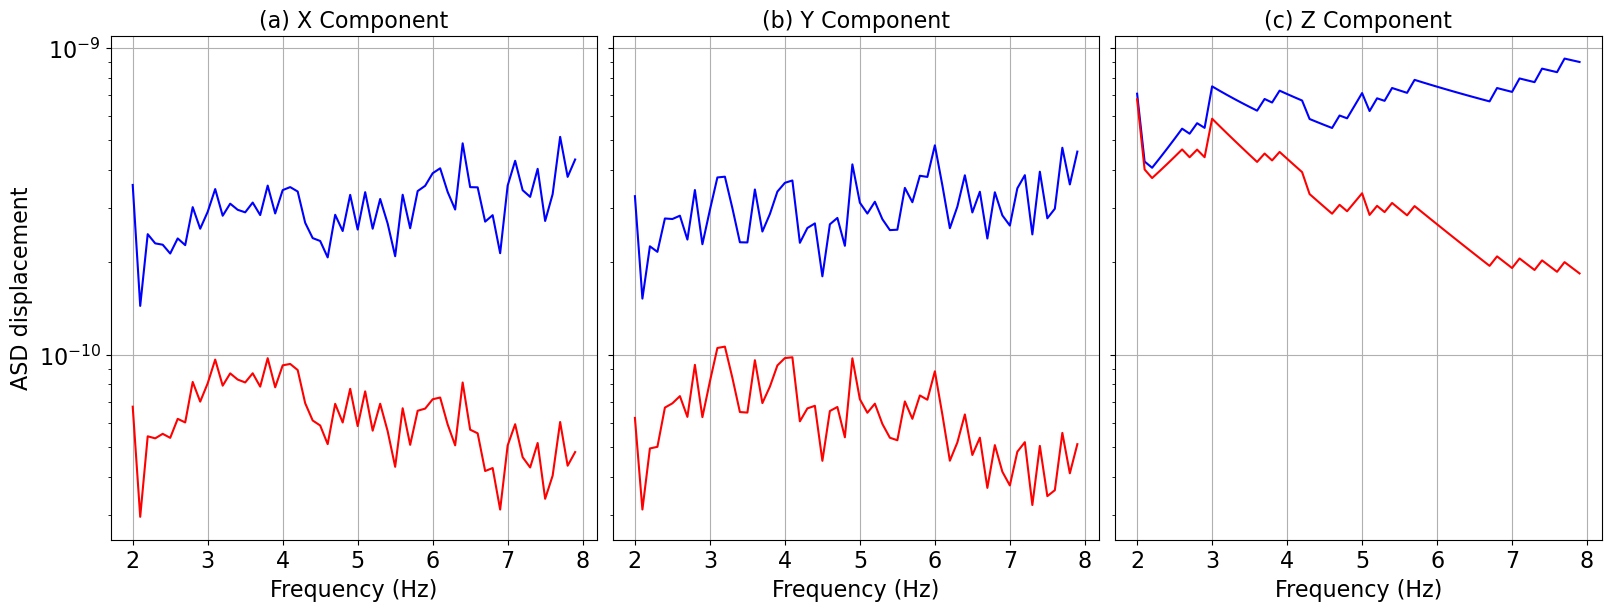

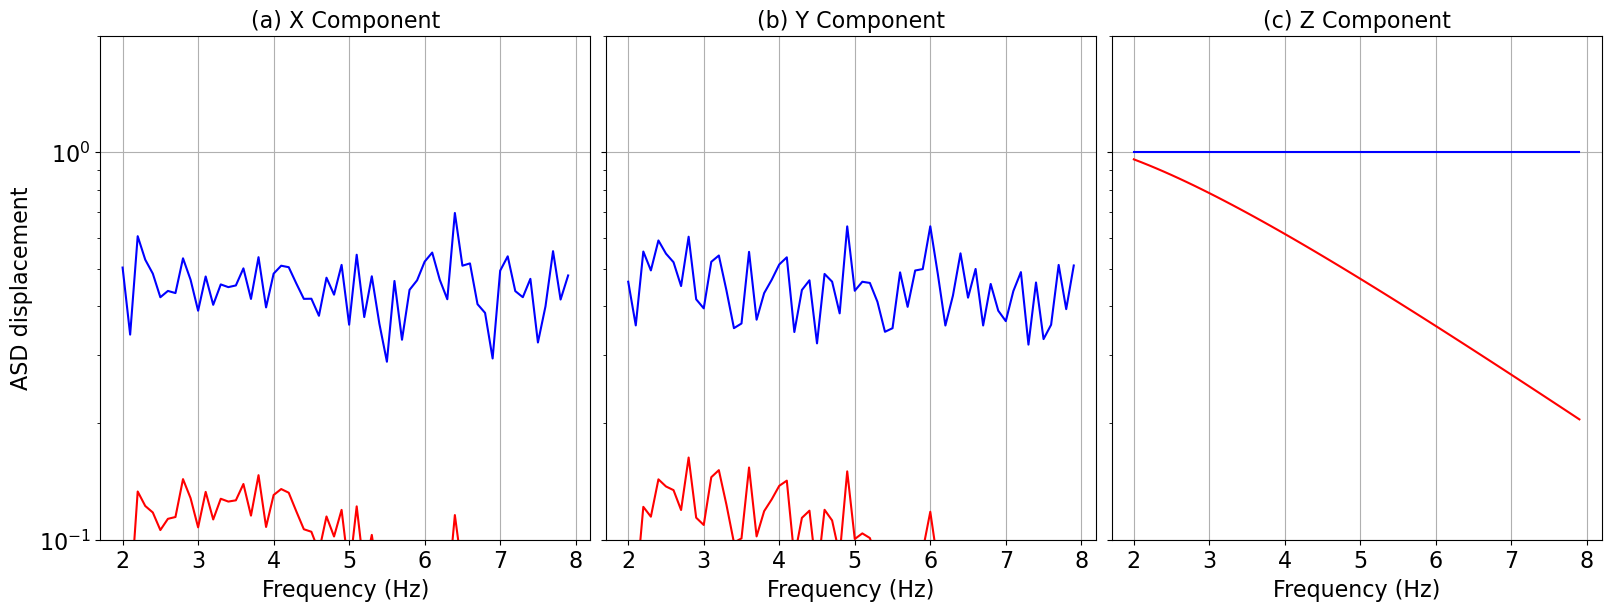

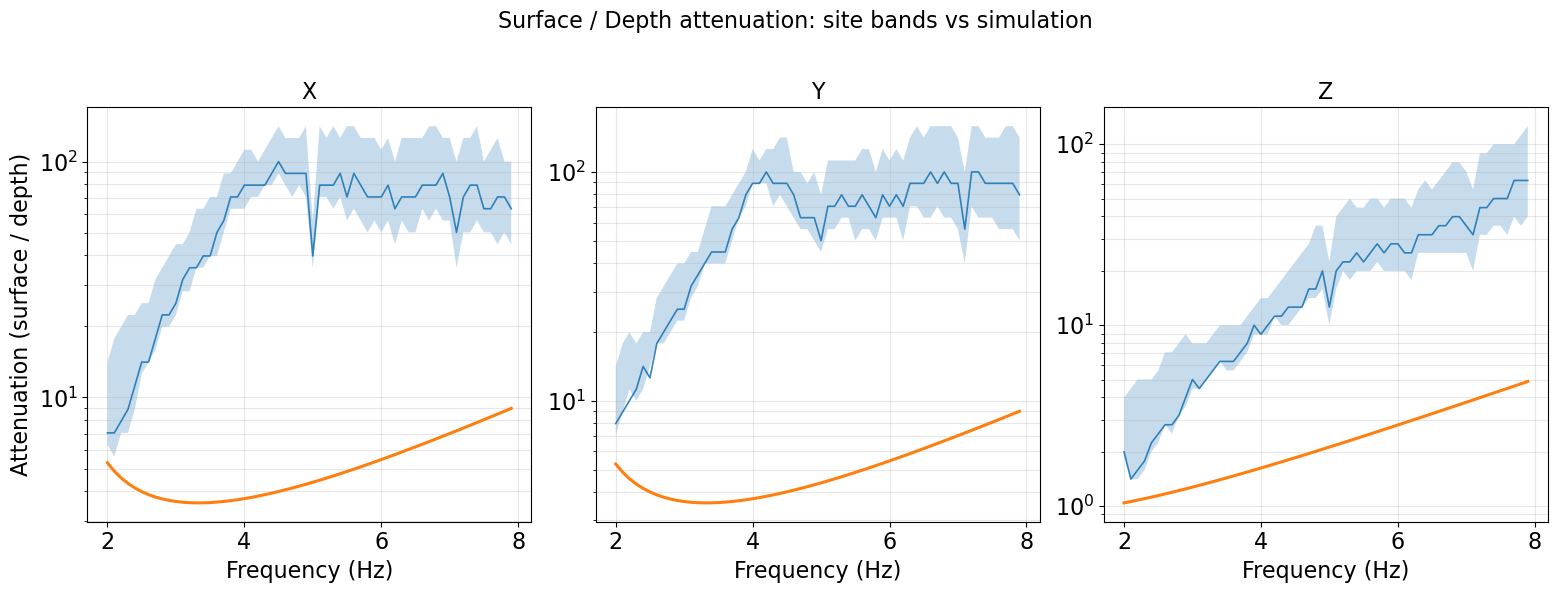

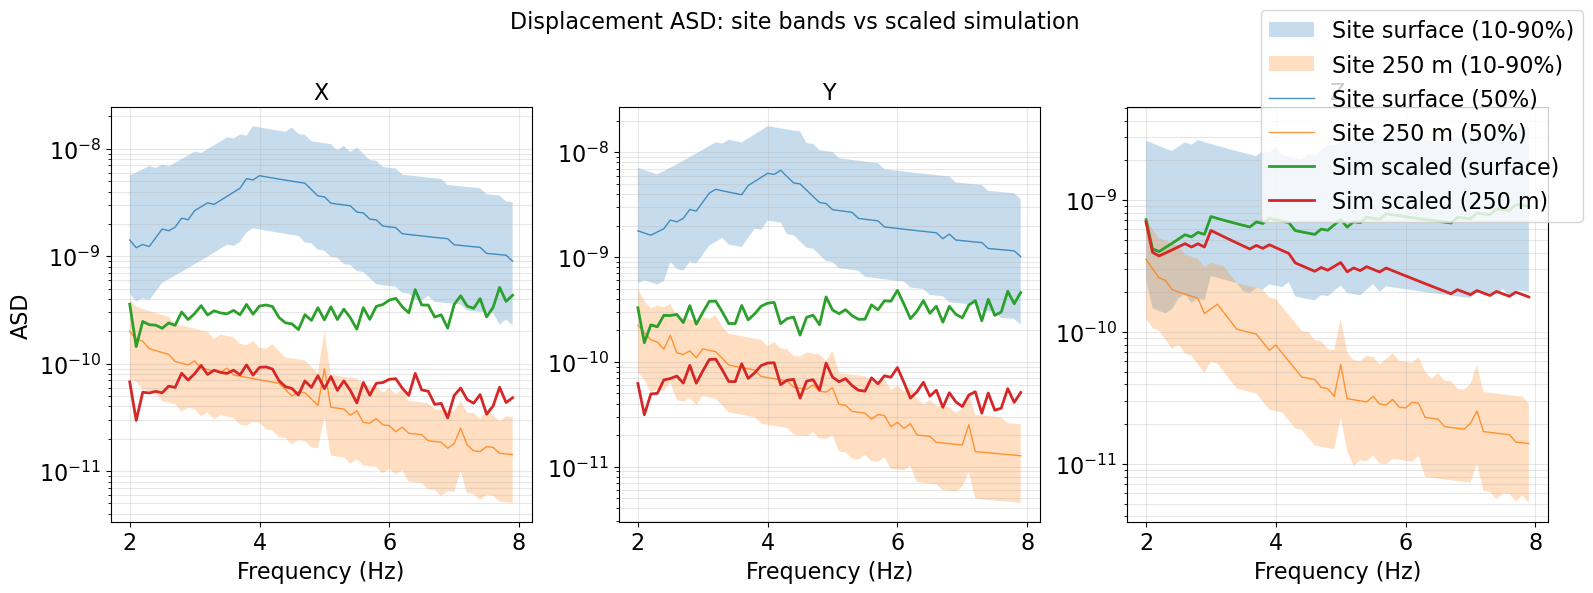

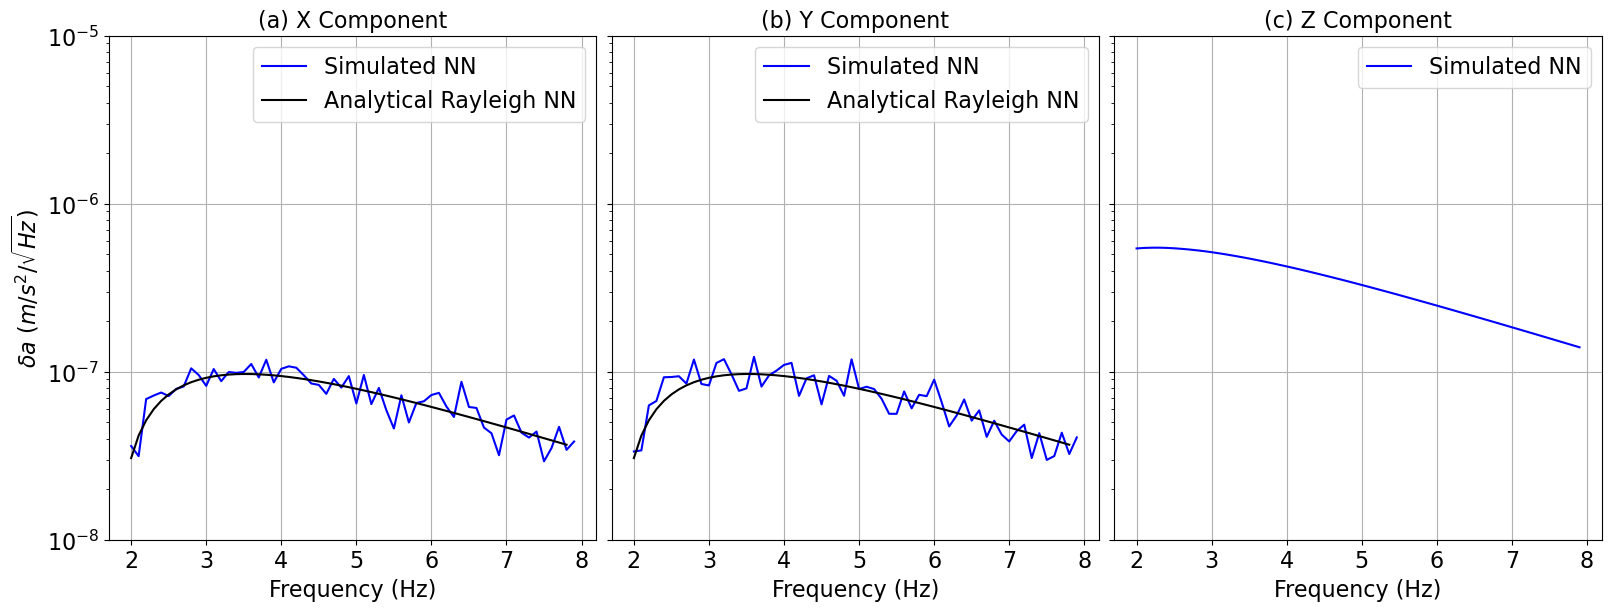

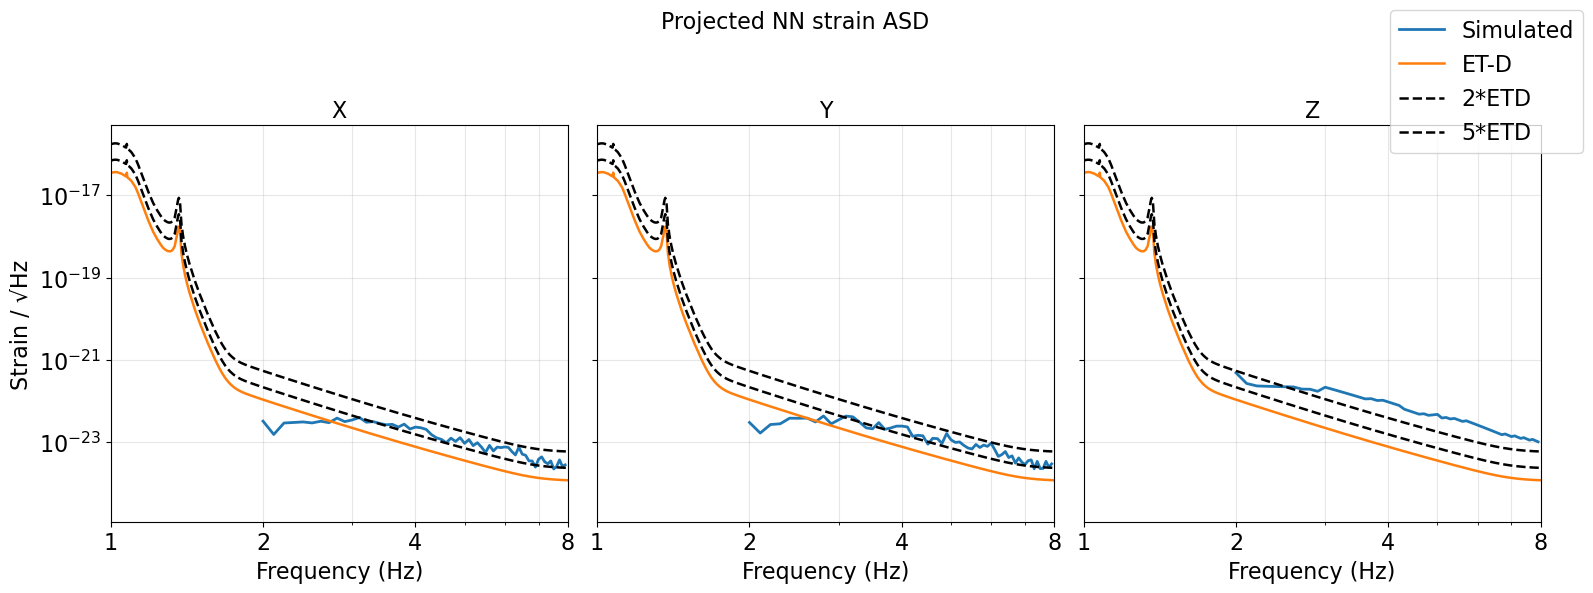

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
import pickle
from scipy.io import loadmat
from modules import configLoader
from modules import validateInputs
from modules import simDisp
from modules import NNCompute
from modules import NNPP
from modules import plotUtils

# set plotting style
plotUtils.set_plot_style(style='medium')
# if firstTime is False there is an existing figure handle, so we load that NN fig handle
# and add the new NN curves to that figure, otherwise we create a new figure
firstTime = True

configFile="/home/koley/CavityResults/SphereRayTutorial/StochWave/configParseHalfSpaceRayHomo.ini"

config = configLoader.load_config(configFile)
    
allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphereRayTutorial/StochWave/SingleSphCavityHalfSpace.ini')
validateInputs.validateInputs(config)
ifRay = config.ifRay
ifBody = config.ifBody

fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
tMax = config.tMax; nSamp = config.nSamp

outDispRea = config.outDispPathRea # like "/data/gravwav/koley/OutDispRea/"

nRea = config.nRea # number of realizations
#nRea = 16

freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
nFreq = len(freqOut)

# new part added
cavDepthAll = np.zeros((len(allCavities),))
for cavNo, cav in enumerate(allCavities):    
    if(cav["shape"]=="cuboid"):
        cavDepthAll[cavNo] = cav["zC"]
    elif(cav["shape"] == 'sphere'):
        cavDepthAll[cavNo] = cav["zC"]
    else:
        raise ValueError('Unsupported cavity type')
    
cavDepthUse = min(cavDepthAll)

itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
itmAll = np.vstack((itmAC,))
nTM = len(itmAll[:,0])

# two depth points for scaling, displacement saved per realization
zList = [0.0,cavDepthUse]

dispPointAllRea, attnAllRea, freqDisp = simDisp.assembleSurfDeepDispAllRea(outDispRea, zList, freqOut, nRea)
    
print(np.shape(dispPointAllRea))
scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ, asdBHX, asdBHY, asdBHZ = NNPP.scaleDisp(
    dispPointAllRea, freqOut, config, scaleComp='Z', scaleDepth = 'surface', scaleToTrue=True)

scaledSimDispFalse, asdSurfXF, asdSurfYF, asdSurfZF, asdBHXF, asdBHYF, asdBHZF = NNPP.scaleDisp(
        dispPointAllRea, freqOut, config, scaleComp='Z', scaleDepth = 'surface', scaleToTrue=False)
    
# make plot
figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,0], '0 m deep', 'b', fig=None, axs=None, 
                                        quantity="ASD displacement")
figDisp, axDisp = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDisp[:,:,1], '250 m deep', 'r', fig=figDisp, axs=axDisp, 
                                        quantity="ASD displacement")
    
figDispF, axDispF = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDispFalse[:,:,0], '0 m deep', 'b', fig=None, axs=None, 
                                         quantity="ASD displacement")
figDispF, axDispF = plotUtils.plotPSDDeepSurfMulti(freqOut, scaledSimDispFalse[:,:,1], '250 m deep', 'r', fig=figDispF, axs=axDispF, 
                                         quantity="ASD displacement")    
axDispF[0].set_ylim(0.1,2);axDispF[1].set_ylim(0.1,2);axDispF[2].set_ylim(0.1,2)
    
attnSim, attnX, attnY, attnZ = NNPP.getAttn(dispPointAllRea,freqOut,config)

figAttn, axAttn = plotUtils.plotAttn(freqOut, attnSim, attnX, attnY, attnZ)
    
figSh, axSh = plotUtils.plotScaledVsSiteASD(freqOut, scaledSimDisp, asdSurfX, asdSurfY, asdSurfZ,
                                                asdBHX, asdBHY, asdBHZ)
    
nnTotAllReaAllTM, nnVolAllReaAllTM, nnSurfAllReaAllTM, fNN = NNCompute.assembleNNAllReaAllTM(outDispRea,freqOut, nRea, nTM)

nnTotAllRea = nnTotAllReaAllTM[:,:,0]
print(np.shape(nnTotAllRea))
scaledNN, *__ = NNPP.scaleNN(nnTotAllRea, dispPointAllRea, freqOut, config, scaleComp="Z",
                             scaleDepth="surface",scaleToTrue=False)

# get the NN analytical curves for Rayleigh and Body waves
NNRay,freqNNRay = NNCompute.getAnalyticRayNN(config,250)
NNBody, minNN, freqNNBody = NNCompute.getAnalyticBodyNN(config,p=1/3)

if(firstTime):
    figNN, axNN = plotUtils.plotPSDDeepSurfMulti(fNN, scaledNN[:,0:3], 'Simulated NN', 'b', fig=None, axs=None, 
                                         quantity=r"$\delta a \ (m/s^2/\sqrt{Hz})$",subFigs=3)
    axNN[0].plot(freqNNRay, NNRay,'k',label='Analytical Rayleigh NN')
    axNN[1].plot(freqNNRay, NNRay,'k',label='Analytical Rayleigh NN')
    
    axNN[0].legend(loc="upper right")
    axNN[1].legend(loc="upper right")
    axNN[2].legend(loc="upper right")
        
    axNN[0].set_ylim(10**-8,10**-5)
    axNN[1].set_ylim(10**-8,10**-5)
    axNN[2].set_ylim(10**-8,10**-5)

scaledNNToTrue, *__ = NNPP.scaleNN(nnTotAllRea, dispPointAllRea, freqOut, config, scaleComp="Z",
                              scaleDepth="surface",scaleToTrue=True)

nnProj, ETD = NNPP.NNProjectToET(scaledNNToTrue, fNN, config)

figSens, axSens = plotUtils.plotNNStrainET(fNN, nnProj, ETD, title="Projected NN strain ASD", xlim=(1, 8), xscale="log",
                   yscale="log", comp_labels=("X", "Y", "Z"), sim_label="Simulated", etd_label="ET-D",
                   legend_once=True, fig=None,axs=None)
